<div align="center">
МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РОССИЙСКОЙ ФЕДЕРАЦИИ
</div>

<div align="center">
ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ<br>
ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ВЫСШЕГО ОБРАЗОВАНИЯ
</div>

<div align="center">
«НОВОСИБИРСКИЙ ГОСУДАРСТВЕННЫЙ ТЕХНИЧЕСКИЙ УНИВЕРСИТЕТ»
</div>

<div align="center">
Кафедра защиты информации
</div>

<br>

<div align="center">
<h1>ОТЧЕТ</h1>
</div>

<div align="center">
<b>по лабораторной работе №2</b>
</div>

<br>

<div align="center">
<b>по дисциплине:</b> «Системы искусственного интеллекта и машинное обучение»
</div>

<div align="center">
<b>Вариант:</b> 2
</div>

<br>
<br>
<br>

| | |
|---|---|
| **Выполнил:** | Студент гр. «АБс-324», «АВТФ» Зенцов А.С. |
| **Дата:** | «\_\_» \_\_\_\_\_\_\_\_\_\_ 2026 г. |
| **Проверил:** | Ассистент ЗИ Питько Я.А. |
| **Дата:** | «\_\_» \_\_\_\_\_\_\_\_\_\_ 2026 г. |
| **Подпись:** | \_\_\_\_\_\_\_\_\_\_\_\_\_\_\_ |

<br>
<br>
<br>

<div align="center">
Новосибирск 2026
</div>

<div align="center">
<h1>Цели и задачи работы</h1>
</div>

**Цель работы:** построить учебный классификатор подозрительных попыток входа, сравнить несколько методов на одном протоколе и выбрать модель с порогом при ограниченной емкости ручной проверки. После выбора один раз оценить зафиксированное решение на внешнем test и объяснить ложные тревоги, пропуски и ограничения результата.

**Задачи работы:**

1. Перенести из ЛР № 1 код чтения и очистки данных (включая замену невалидных категориальных значений на `unknown` и удаление полных дубликатов), перечень признаков, схему разделения и состав внешнего test.
2. Воспроизвести внешний test ЛР № 1 и выделить validation только из прежнего train.
3. Обучить baseline и три классификатора: по одной исходной настройке и одному заранее обоснованному изменению гиперпараметра.
4. Сравнить конфигурации на validation по бинарным метрикам и AP по score.
5. Выбрать рабочую точку `score >= threshold` при лимите алертов и посчитать учебную стоимость `cost = FP + 20*FN`.
6. Зафиксировать решение, один раз проверить его на test, разобрать ошибки и сформулировать вывод с ограничениями.

<div align="center">
<h1>Вариант, объект анализа и данные</h1>
</div>

**Вариант:** 2 (сохраняется вариант ЛР № 1). Сценарий проверки: новые учетные записи, ключ группы `user_id`. Validation выделяется из прежнего train как около 25% оставшихся групп `user_id` через `GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43)`. Дополнительный разбор: ошибки по `auth_method` и значения `failed_attempts_24h` у примеров FN.

**Объект анализа:** одна попытка аутентификации (одна строка). Учетная запись дает несколько строк, поэтому объект анализа не совпадает с пользователем.

**Целевая переменная:** `is_suspicious`, где класс 1 - подозрительное событие по учебной разметке, класс 0 - нормальная попытка. Score - одно число на событие, большее значение означает более выраженный класс 1; score не является вероятностью подтвержденной атаки. Алерт - бинарное решение `score >= threshold`, которое попадает на ручную проверку.

**Данные:** синтетический набор `auth_events_lab01.xlsx`, лист `data`, 1430 строк × 23 столбца, период 2026-01-01 … 2026-03-31, персональных данных не содержит. Разметка учебная, поэтому «подозрительное по разметке» не равно «подтвержденная атака».

**Что переносится из ЛР № 1:** код чтения файла; правила очистки (типы, неисправимые значения, замена невалидных категориальных значений на `unknown`, удаление полных технических дубликатов); перечень признаков; групповая схема разделения по `user_id`; внешний test (те же строки, 80/20, `random_state=42`).

**Что обучается заново:** медианы, моды, масштаб и состав категорий one-hot кодирования. Готовые `X_train_ready` / `X_test_ready` и `artifacts/preprocessor.joblib` из ЛР № 1 не используются: прежний препроцессор обучался на всей старой обучающей части, в которую теперь входит validation. Каждый опыт получает новый необученный `Pipeline`, `fit` вызывается только на train.

<div align="center">
<h1>Подготовка проекта: окружение и воспроизводимость</h1>
</div>

Все пути относительные; Notebook выполняется через Restart Kernel / Run All из каталога `lab02_ABs324_Zentsov`, результаты не зависят от переменных, оставленных в памяти вручную. Версии библиотек печатаются ниже.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt

RANDOM_STATE = 42          # исходное разбиение ЛР № 1 и random_state моделей
RS_VALID = 43              # выделение validation внутри старого train (вариант 2)
ALERT_LIMIT_SHARE = 0.12   # не более 120 алертов на 1000 событий
FN_COST = 20               # стоимость пропуска относительно ложной тревоги

DATA_PATH = Path('data/auth_events_lab01.xlsx')
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)

print(sys.version)
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('matplotlib  :', matplotlib.__version__)
print('файл данных существует:', DATA_PATH.exists())

Matplotlib is building the font cache; this may take a moment.


3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
pandas      : 3.1.1
numpy       : 2.5.4
scikit-learn: 1.9.1
matplotlib  : 3.11.2
файл данных существует: True


<div align="center">
<h1>1. Перенос аудита: паспорт данных</h1>
</div>

Служебный столбец `source_row_id` - номер строки исходного файла; он создается до любой фильтрации, не входит в признаки и не участвует в поиске дубликатов.

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name='data')
# df - рабочая копия
df = raw.copy()
# служебный номер строки исходного файла: до очистки, в признаки не входит
df.insert(0, 'source_row_id', np.arange(len(df)))

ORIG_ROWS, ORIG_COLS = len(df), raw.shape[1]
ts_raw = pd.to_datetime(df['timestamp'], errors='coerce', format='mixed')
ts_txt = df['timestamp'].astype('string')
ts_not_empty = ts_txt.notna() & ts_txt.str.strip().ne('')

print(f'Исходный файл : {ORIG_ROWS} строк, {ORIG_COLS} содержательных столбцов (+ source_row_id)')
print('Пользователей (user_id) :', df['user_id'].nunique())
print('Период наблюдений       :', ts_raw.min().date(), '...', ts_raw.max().date())
print('Невалидных непустых timestamp:', int((ts_not_empty & ts_raw.isna()).sum()), 'не читается +',
      int((ts_raw.notna() & (df['hour'] != ts_raw.dt.hour)).sum()), 'противоречит hour')
print('Полных дубликатов строк :', int(df.drop(columns=['source_row_id']).duplicated().sum()))
print('Строк с event_id evt_retry_* :', int(df['event_id'].astype('string').str.startswith('evt_retry').sum()))

print('\nСтолбцы, типы и пропуски в исходном файле:')
display(pd.DataFrame({
    'dtype': df.drop(columns=['source_row_id']).dtypes.astype(str),
    'непустых': df.drop(columns=['source_row_id']).notna().sum(),
    'пропусков': df.drop(columns=['source_row_id']).isna().sum(),
}))

print('\nБаланс классов is_suspicious (до очистки):')
print(df['is_suspicious'].value_counts().to_string())
print('доля класса 1: {:.2%}'.format(df['is_suspicious'].mean()))

Исходный файл : 1430 строк, 23 содержательных столбцов (+ source_row_id)
Пользователей (user_id) : 120
Период наблюдений       : 2026-01-01 ... 2026-03-31
Невалидных непустых timestamp: 3 не читается + 1 противоречит hour
Полных дубликатов строк : 18
Строк с event_id evt_retry_* : 12

Столбцы, типы и пропуски в исходном файле:


,dtype,непустых,пропусков
event_id,str,1430,0
timestamp,object,1430,0
user_id,str,1430,0
department,str,1416,14
source_ip,str,1430,0
country,str,1430,0
device_type,str,1430,0
os_family,str,1430,0
browser_family,str,1400,30
auth_method,str,1430,0



Баланс классов is_suspicious (до очистки):
is_suspicious
0    1301
1     129
доля класса 1: 9.02%


**Паспорт данных (сводка):**

| Параметр | Значение |
|---|---|
| Источник | `data/auth_events_lab01.xlsx`, лист `data` |
| Объем | 1430 строк * 23 содержательных столбца |
| Объект строки | одна попытка аутентификации |
| Период | 2026-01-01 … 2026-03-31 |
| Учетных записей `user_id` | 120 |
| Целевая метка | `is_suspicious` - значения {0, 1}, класс 1 - подозрительное событие (9.02% до очистки) |
| Пустые ячейки | 76 в исходном файле; после перевода нечитаемых и нефизичных значений в `NaN` - 101 в 7 столбцах |
| Невалидные непустые значения | `timestamp` **4** → `NaT`; `password_age_days` 9, `failed_attempts_24h` 5, `distance_from_usual_km` 4, `account_age_days` 3 → `NaN`; `browser_family` 10 и `department` 8 → категория `unknown` |
| Полные дубликаты | 18 строк |

Ниже те же правила очистки применяются к данным с фиксацией числа затронутых строк.

<div align="center">
<h1>2. Техническая очистка данных</h1>
</div>

**2.1. Поиск невалидных значений для числовых признаков и их обработка**
* типы приводятся к машинным;
* нефизичные и технические значения (отрицательные, нечитаемые) заменяются на `NaN` и затем обрабатываются импутером внутри конвейера;
* строки по этим правилам не удаляются.

In [1]:
audit = []  # (проблема, правило обработки, число затронутых строк)

# 1. timestamp -> datetime64[ns]; нечитаемые непустые метки -> NaT
TS_RAW_STR = df['timestamp'].astype('string')      # исходный текст метки: нужен для аудита
TS_NOT_EMPTY = TS_RAW_STR.notna() & TS_RAW_STR.str.strip().ne('')
ts = pd.to_datetime(df['timestamp'], errors='coerce', format='mixed')
TS_UNREADABLE = TS_NOT_EMPTY & ts.isna()           # невалидная непустая метка: не читается как дата
audit.append(('timestamp: невалидное непустое значение (не читается)',
              'переведено в NaT (datetime64[ns])', int(TS_UNREADABLE.sum())))
df['timestamp'] = ts

print('Непустых значений timestamp            :', int(TS_NOT_EMPTY.sum()), 'из', len(df))
print('Из них не читается (переведено в NaT)  :', int(TS_UNREADABLE.sum()),
      '->', sorted(TS_RAW_STR[TS_UNREADABLE].unique()))

# 2. password_age_days: текстовая метка -> NaN, числовой тип
pa = pd.to_numeric(df['password_age_days'], errors='coerce')
audit.append(('password_age_days: нечисловые значения', 'переведены в NaN (float64)', int(pa.isna().sum())))
df['password_age_days'] = pa

# 3. failed_attempts_24h: ложные значения в виде 999 (принимаем за ошибку сием) и отрицательные значения
mask_999 = df['failed_attempts_24h'] == 999
mask_neg = df['failed_attempts_24h'] < 0
audit.append(('failed_attempts_24h = 999 (заглушка)', 'значение нефизично -> NaN', int(mask_999.sum())))
audit.append(('failed_attempts_24h < 0', 'значение нефизично -> NaN', int(mask_neg.sum())))
df.loc[mask_999 | mask_neg, 'failed_attempts_24h'] = np.nan

# 4. distance_from_usual_km < 0
mask = df['distance_from_usual_km'] < 0
audit.append(('distance_from_usual_km < 0', 'значение нефизично -> NaN', int(mask.sum())))
df.loc[mask, 'distance_from_usual_km'] = np.nan

# 5. account_age_days < 0
mask = df['account_age_days'] < 0
audit.append(('account_age_days < 0', 'значение нефизично -> NaN', int(mask.sum())))
df.loc[mask, 'account_age_days'] = np.nan

print('Пустых ячеек после перевода неисправимых значений в NaN:',
      int(df.isna().sum().sum()))
print(df[['password_age_days', 'failed_attempts_24h',
          'distance_from_usual_km', 'account_age_days']].describe().round(2).to_string())

NameError: name 'df' is not defined

**2.1. Поиск невалидных значений для категориальных признаков и их обработка**

У каждого категориального признака есть отдельная категория `unknown`, куда попадает все, что не входит в справочник ("-", "?", опечатки, другой регистр). Для каждого категориального признака задан закрытый справочник допустимых значений.

* непустое значение вне справочника (включая "-", "?", "unknown", опечатки, другой регистр) заменяется на единую категорию `unknown`;
* пустая ячейка (`NaN`, пустая строка, строка из пробелов) остается пустой и заполняется наиболее частым значением внутри конвейера, обученного только на train;
* сравнение точное (с учетом регистра), пробелы по краям обрезаются.

Справочники покрывают все значения файла, поэтому `unknown` не заменяет настоящие категории, а собирает только нераспознанные значения.

In [4]:
ALLOWED_CATEGORIES = {
    'department':     ['SOC', 'R&D', 'HR', 'Operations', 'IT', 'Sales', 'Finance'],
    'country':        ['NO', 'DE', 'SE', 'NL', 'US', 'PL', 'RU', 'BR', 'CN'],
    'device_type':    ['mobile', 'tablet', 'laptop', 'desktop'],
    'os_family':      ['Android', 'Windows', 'iOS', 'macOS', 'Linux'],
    'browser_family': ['Chrome', 'Safari', 'Edge', 'Firefox'],
    'auth_method':    ['password', 'push', 'otp', 'fido2'],
}
UNKNOWN_CATEGORY = 'unknown'
CATEGORICAL_COLUMNS = list(ALLOWED_CATEGORIES)


def normalize_category(series, allowed):
    """Пустые ячейки остаются пустыми, непустые значения вне справочника -> 'unknown'."""
    allowed = set(allowed)

    def convert(value):
        if not isinstance(value, str):          # NaN и не-строки остаются как есть
            return value
        value = value.strip()                   # пробелы по краям значением не считаются
        if value == '':                         # пустая строка == пустая ячейка
            return np.nan
        if value not in allowed:                # непустое значение вне справочника
            return UNKNOWN_CATEGORY
        return value

    return series.map(convert).astype(object)


# Аудит правила: сколько пустых ячеек, сколько невалидных непустых и какие именно значения
cat_audit, invalid_masks = [], {}
for col, allowed in ALLOWED_CATEGORIES.items():
    before = df[col].copy()
    stripped = before.map(lambda v: v.strip() if isinstance(v, str) else v)
    is_empty = stripped.map(lambda v: isinstance(v, str) and v == '')
    is_invalid = stripped.map(lambda v: isinstance(v, str) and v != '' and v not in set(allowed))
    invalid_masks[col] = is_invalid
    counts = stripped[is_invalid].value_counts()
    cat_audit.append({
        'Столбец': col,
        'Допустимых': len(allowed),
        'Пустых ячеек (NaN)': int(before.isna().sum()),
        'Пустых строк': int(is_empty.sum()),
        'Невалидных непустых': int(is_invalid.sum()),
        'Переведено в unknown': ', '.join(f'{v!r} x{c}' for v, c in counts.items()) or '-',
    })

CAT_AUDIT = pd.DataFrame(cat_audit).set_index('Столбец')
display(CAT_AUDIT)

any_invalid = pd.concat(invalid_masks, axis=1).any(axis=1)
print('Строк, где хотя бы одна категория заменена на unknown:', int(any_invalid.sum()))

# Проверка покрытия: все ли значения файла перечислены в справочниках
cover = []
for col, allowed in ALLOWED_CATEGORIES.items():
    values = df[col].map(lambda v: v.strip() if isinstance(v, str) else v).dropna().unique()
    extra = sorted({str(v) for v in values} - set(allowed))
    cover.append({'Столбец': col, 'Уникальных значений в файле': len(values),
                  'Значения вне справочника': ', '.join(extra) or '-'})
display(pd.DataFrame(cover).set_index('Столбец'))

# Применяем правило ко всем категориальным признакам
for col in CATEGORICAL_COLUMNS:
    df[col] = normalize_category(df[col], ALLOWED_CATEGORIES[col])

,Допустимых,Пустых ячеек (NaN),Пустых строк,Невалидных непустых,Переведено в unknown
Столбец,,,,,
department,7,14,0,8,'unknown' x8
country,9,0,0,0,-
device_type,4,0,0,0,-
os_family,5,0,0,0,-
browser_family,4,30,0,10,'-' x10
auth_method,4,0,0,0,-


Строк, где хотя бы одна категория заменена на unknown: 18


,Уникальных значений в файле,Значения вне справочника
Столбец,,
department,8,unknown
country,9,-
device_type,4,-
os_family,5,-
browser_family,5,-
auth_method,4,-


In [5]:
print('Распределение категориальных признаков после нормализации:')
for col in CATEGORICAL_COLUMNS:
    vc = df[col].value_counts(dropna=False)
    labels = []
    for key in vc.index:
        try:
            labels.append('<NaN>' if pd.isna(key) else str(key))
        except (TypeError, ValueError):
            labels.append(str(key))
    pairs = ', '.join(f'{lab}={cnt}' for lab, cnt in zip(labels, vc.values))
    print(f'{col:15s} (NaN={int(df[col].isna().sum()):3d}, '
          f'unknown={int((df[col] == UNKNOWN_CATEGORY).sum()):3d}): {pairs}')

Распределение категориальных признаков после нормализации:
department      (NaN= 14, unknown=  8): SOC=269, R&D=248, HR=196, Operations=179, IT=176, Sales=174, Finance=166, <NaN>=14, unknown=8
country         (NaN=  0, unknown=  0): NO=393, DE=268, SE=257, NL=188, US=135, PL=95, RU=80, BR=8, CN=6
device_type     (NaN=  0, unknown=  0): mobile=491, tablet=334, laptop=329, desktop=276
os_family       (NaN=  0, unknown=  0): Android=464, Windows=409, iOS=361, macOS=123, Linux=73
browser_family  (NaN= 30, unknown= 10): Chrome=793, Safari=263, Edge=182, Firefox=152, <NaN>=30, unknown=10
auth_method     (NaN=  0, unknown=  0): password=571, push=372, otp=330, fido2=157


**Итог правила.** В файле 10 непустых значений `browser_family` вне справочника и 8 значений `department` вне справочника - все 18 строк получают единую категорию `unknown`; пустые ячейки (`browser_family` 30, `department` 14) остаются пустыми и заполняются модой внутри конвейера. Категория `unknown` объявляется в one-hot кодировщике заранее (раздел 4, `OneHotEncoder(categories=...)`): словарь строится из справочника, а не из train, поэтому метка «не распознано» есть в модели всегда, даже если в train таких строк не оказалось. Это фиксированное предметное правило, а не оценка по данным, поэтому утечки нет.

**2.3. Проверка непустых меток времени.** Признаки `hour` и `is_weekend` должны соответствовать `timestamp`, а `hour` участвует в модели, поэтому согласованность проверяется.

Невалидных непустых меток в файле 4 из 1430: три не читаются как дата (раздел 2.1) и одна читается, но противоречит остальным полям записи - `source_row_id = 422`, метка 2026-03-17 13:45 при `hour = 22`. Какое из двух полей испорчено, по данным установить нельзя: и 13:45, и 22:00 вторника физически допустимы, а `is_weekend = 0` согласован с обеими версиями. Поэтому метка не восстанавливается подстановкой одного поля в другое: она переводится в `NaT`, а `hour` и `is_weekend` остаются как в файле. Значения в `X` не выдумываются, строка сохраняется, состав test не меняется; сама метка в признаки не входит (раздел 3.1).

**2.4. Полные технические дубликаты.** Как и в ЛР № 1, удаляются полные повторы строк; служебный `source_row_id` в сравнении не участвует, иначе повторы перестали бы находиться.

In [6]:
# 2.3. Валидация непустых меток времени: не читается / противоречит hour / is_weekend
ts = df['timestamp']
hour_from_ts = ts.dt.hour
weekend_from_ts = ts.dt.dayofweek.isin([5, 6])
bad_hour = ts.notna() & (df['hour'] != hour_from_ts)
bad_weekend = ts.notna() & (df['is_weekend'].astype('Int64') != weekend_from_ts.astype('Int64'))

TS_ISSUES = pd.DataFrame([
    {'Вид невалидного непустого timestamp': 'не читается как дата (раздел 2.1)',
     'Строк': int(TS_UNREADABLE.sum()),
     'Обработка': 'метка -> NaT; hour и is_weekend остаются как в файле'},
    {'Вид невалидного непустого timestamp': 'читается, но противоречит hour',
     'Строк': int(bad_hour.sum()),
     'Обработка': 'метка -> NaT; hour остается как в файле'},
    {'Вид невалидного непустого timestamp': 'читается, но противоречит is_weekend',
     'Строк': int(bad_weekend.sum()),
     'Обработка': 'метка -> NaT; is_weekend остается как в файле'},
])
display(TS_ISSUES)
INVALID_TS = int(TS_ISSUES['Строк'].sum())
print('Непустых timestamp всего           :', int(TS_NOT_EMPTY.sum()))
print('Невалидных непустых timestamp всего:', INVALID_TS,
      f'({int(TS_UNREADABLE.sum())} не читается + {int(bad_hour.sum())} противоречит hour)')
assert INVALID_TS == int((TS_UNREADABLE | bad_hour | bad_weekend).sum()), 'виды проблем времени пересекаются'

if (bad_hour | bad_weekend).any():
    print('\nЗаписи, где метка времени противоречит полям записи:')
    display(df.loc[bad_hour | bad_weekend, ['source_row_id', 'event_id', 'timestamp', 'hour', 'is_weekend']])

audit.append(('timestamp: невалидное непустое значение (противоречит hour)',
              'метка -> NaT; hour остается как в файле', int(bad_hour.sum())))
audit.append(('timestamp: невалидное непустое значение (противоречит is_weekend)',
              'метка -> NaT; is_weekend остается как в файле', int(bad_weekend.sum())))
df.loc[bad_hour | bad_weekend, 'timestamp'] = pd.NaT

# Удаление полных технических дубликатов
dup_mask = df.drop(columns=['source_row_id']).duplicated(keep='first')
audit.append(('полные дубликаты строк', 'удалены повторы (keep="first")', int(dup_mask.sum())))
ROWS_BEFORE_DEDUP = len(df)
df = df.loc[~dup_mask].reset_index(drop=True)

print(f'\nСтрок до удаления дубликатов : {ROWS_BEFORE_DEDUP}')
print(f'Строк после очистки          : {len(df)}  (удалено {int(dup_mask.sum())})')
print('Класс 1 после очистки        :', int(df['is_suspicious'].sum()),
      '({:.2%})'.format(df['is_suspicious'].mean()))

# Состав пустых ячеек: отдельно служебный timestamp, который в матрицу признаков не входит
na_by_col = df.isna().sum()
na_by_col = na_by_col[na_by_col > 0]
print('\nПустые ячейки после очистки по столбцам:')
print(na_by_col.to_string())
print('Всего пустых ячеек          :', int(na_by_col.sum()), 'в', len(na_by_col), 'столбцах;',
      'из них', int(na_by_col.get('timestamp', 0)), '- в служебном timestamp (в признаки не входит)')

print('\nСводная таблица «проблема - правило обработки - число затронутых строк»:')
AUDIT = pd.DataFrame(audit, columns=['Проблема', 'Правило обработки', 'Затронуто строк'])
display(AUDIT)
print('Итого затронуто строк (сумма по правилам, строки могут пересекаться):',
      int(AUDIT['Затронуто строк'].sum()))

C:\Users\jrzen\AppData\Local\Temp\ipykernel_14176\2832606284.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekend_from_ts = ts.dt.dayofweek.isin([5, 6])


,Вид невалидного непустого timestamp,Строк,Обработка
0,не читается как дата (раздел 2.1),3,метка -> NaT; hour и is_weekend остаются как в...
1,"читается, но противоречит hour",1,метка -> NaT; hour остается как в файле
2,"читается, но противоречит is_weekend",0,метка -> NaT; is_weekend остается как в файле


Непустых timestamp всего           : 1430
Невалидных непустых timestamp всего: 4 (3 не читается + 1 противоречит hour)

Записи, где метка времени противоречит полям записи:


,source_row_id,event_id,timestamp,hour,is_weekend
422,422,evt_001299,2026-03-17 13:45:00,22,0



Строк до удаления дубликатов : 1430
Строк после очистки          : 1412  (удалено 18)
Класс 1 после очистки        : 126 (8.92%)

Пустые ячейки после очистки по столбцам:
timestamp                  4
department                14
browser_family            30
failed_attempts_24h        5
distance_from_usual_km    36
account_age_days           3
password_age_days          9
Всего пустых ячеек          : 101 в 7 столбцах; из них 4 - в служебном timestamp (в признаки не входит)

Сводная таблица «проблема - правило обработки - число затронутых строк»:


,Проблема,Правило обработки,Затронуто строк
0,timestamp: невалидное непустое значение (не чи...,переведено в NaT (datetime64[ns]),3
1,password_age_days: нечисловые значения,переведены в NaN (float64),9
2,failed_attempts_24h = 999 (заглушка),значение нефизично -> NaN,2
3,failed_attempts_24h < 0,значение нефизично -> NaN,3
4,distance_from_usual_km < 0,значение нефизично -> NaN,4
5,account_age_days < 0,значение нефизично -> NaN,3
6,timestamp: невалидное непустое значение (проти...,метка -> NaT; hour остается как в файле,1
7,timestamp: невалидное непустое значение (проти...,метка -> NaT; is_weekend остается как в файле,0
8,полные дубликаты строк,"удалены повторы (keep=""first"")",18


Итого затронуто строк (сумма по правилам, строки могут пересекаться): 43


**Итог раздела 2.** Правила зафиксированы до разделения данных, не используют целевую переменную и не подбираются по test. После очистки: 1412 строк, 101 пустая ячейка - 97 в признаках (импутируются внутри конвейера) и 4 в служебном `timestamp`, который в `X` не входит; 4 невалидных непустых метки времени переведены в `NaT`, 18 невалидных непустых категориальных значений - в `unknown`; класс 1 - 126 событий (8.92%).

<div align="center">
<h1>3. Признаки и разделение данных</h1>
</div>

**3.1. Перечень признаков переносится из ЛР № 1.** В матрицу `X` входят 10 числовых и 6 категориальных признаков. В `X` не входят:

* результаты расследования `analyst_verdict` и `analyst_risk_score` - в момент входа они неизвестны, и модель воспроизводила бы готовый ответ;
* служебные и идентифицирующие поля: `event_id` (не уникален), `source_ip` (идентификатор сети), `user_id` (ключ группы, участвует только в разделении), `timestamp` (нужен для проверки `hour` и `is_weekend`);
* целевая переменная `is_suspicious`.

`hour` и `is_weekend` остаются в модели после проверки согласованности с `timestamp` (раздел 2.3). Сама метка в `X` не входит, поэтому 4 значения, переведенные в `NaT`, модель не затрагивают.

**Допущение:** `failed_attempts_24h`, `login_velocity_1h`, `distance_from_usual_km`, `new_country`, `vpn_used`, `known_device` считаются доступными в момент решения - это агрегаты по прошлым событиям, а не последствия текущего входа. Для набора это допущение, и оно вынесено в ограничения.

In [7]:
TARGET = 'is_suspicious'
GROUP_COLUMN = 'user_id'
LEAK_COLUMNS = ['analyst_verdict', 'analyst_risk_score']
SERVICE_COLUMNS = ['source_row_id', 'event_id', 'timestamp', 'source_ip']

NUMERIC_FEATURES = ['hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h',
                    'distance_from_usual_km', 'new_country', 'vpn_used', 'known_device',
                    'password_age_days', 'account_age_days']
CATEGORICAL_FEATURES = CATEGORICAL_COLUMNS          # 6 категориальных признаков из раздела 2.2
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].astype(int)
groups = df[GROUP_COLUMN].astype(object)

display(pd.DataFrame({'Признак': FEATURES,
                      'Тип': (['числовой'] * len(NUMERIC_FEATURES)
                              + ['категориальный'] * len(CATEGORICAL_FEATURES)),
                      'Пропусков в X': [int(X[c].isna().sum()) for c in FEATURES]}))
print('Исключены из X:', [c for c in df.columns if c not in FEATURES + [TARGET, GROUP_COLUMN]])
print('Утечки разметки:', LEAK_COLUMNS, '| Служебные:', SERVICE_COLUMNS)
print('X:', X.shape, '| y:', y.shape, '| групп user_id:', groups.nunique())
print('Пропусков в X всего:', int(X.isna().sum().sum()))

,Признак,Тип,Пропусков в X
0,hour,числовой,0
1,is_weekend,числовой,0
2,failed_attempts_24h,числовой,5
3,login_velocity_1h,числовой,0
4,distance_from_usual_km,числовой,36
5,new_country,числовой,0
6,vpn_used,числовой,0
7,known_device,числовой,0
8,password_age_days,числовой,9
9,account_age_days,числовой,3


Исключены из X: ['source_row_id', 'event_id', 'timestamp', 'source_ip', 'analyst_verdict', 'analyst_risk_score']
Утечки разметки: ['analyst_verdict', 'analyst_risk_score'] | Служебные: ['source_row_id', 'event_id', 'timestamp', 'source_ip']
X: (1412, 16) | y: (1412,) | групп user_id: 120
Пропусков в X всего: 97


**3.2. Воспроизведение внешнего test ЛР № 1.** Разделение остается групповым по `user_id`: события одной учетной записи связаны, и при перемешивании строк события одного пользователя попали бы и в train, и в test, а метрики test стали бы оптимистичнее. Код очистки и правило категорий те же, что в ЛР № 1 (разделы 2 и 2.2), поэтому test восстанавливается тем же вызовом: `GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)` по группам `user_id`, то есть 80/20 от тех же 1412 строк. Состав сверяется с отчетом ЛР № 1 по двум числам - 262 строки и 24 группы, - а номера строк сохраняются в `split_ids.csv` по `source_row_id`, чтобы дальше проверять принадлежность строк без повторного разделения.

In [8]:
from sklearn.model_selection import GroupShuffleSplit

# 80/20, группы user_id, random_state=42 (train, test для ЛР № 2)
# idx_old_train - индексы строк, которые попали в train по новой обработке
# idx_test - индексы строк, которые попали в test по новой обработке
idx_old_train, idx_test = next(
    GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE).split(X, y, groups=groups))

# сверка с отчетом ЛР № 1: там в test было 262 строки и 24 группы user_id
LAB01_TEST_ROWS, LAB01_TEST_GROUPS = 262, 24
test_rows, test_users = len(idx_test), df.loc[idx_test, 'user_id'].nunique()
print('Строк после очистки  :', len(df))
print('Строк в test         :', test_rows, '| в отчете ЛР № 1:', LAB01_TEST_ROWS,
      '->', test_rows == LAB01_TEST_ROWS)
print('Групп user_id в test :', test_users, '| в отчете ЛР № 1:', LAB01_TEST_GROUPS,
      '->', test_users == LAB01_TEST_GROUPS)
print('Класс 1 в test       :', int(y.iloc[idx_test].sum()),
      '({:.2%})'.format(y.iloc[idx_test].mean()))

Строк после очистки  : 1412
Строк в test         : 262 | в отчете ЛР № 1: 262 -> True
Групп user_id в test : 24 | в отчете ЛР № 1: 24 -> True
Класс 1 в test       : 18 (6.87%)


**3.3. Validation только из прежнего train (вариант 2).** Validation выделяется внутри прежней обучающей части (`GroupShuffleSplit`, `test_size=0.25`, `random_state=43`, группы `user_id`); test в этом шаге не участвует. Принадлежность строк проверяется по `source_row_id` и по группам, строк вне частей нет, так как полные дубликаты удалены при очистке.

In [9]:
# делим старый train (1150 строк) на две части 75% и 25% (на новый train (862) и validation (288) )
# sub_train, sub_val - это индексы внутри idx_old_train
sub_train, sub_val = next(
    GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RS_VALID)
    .split(X.iloc[idx_old_train], y.iloc[idx_old_train], groups=groups.iloc[idx_old_train]))
# idx_train = idx_old_train[sub_train] - новый train, индексы внутри df
# idx_val = idx_old_train[sub_val] - validation, индексы внутри df.
idx_train, idx_val = idx_old_train[sub_train], idx_old_train[sub_val]
IDX_TEST = idx_test

X_train, y_train = X.iloc[idx_train], y.iloc[idx_train]
X_val, y_val = X.iloc[idx_val], y.iloc[idx_val]
X_test, y_test = X.iloc[idx_test], y.iloc[idx_test]

PARTS = {'train': idx_train, 'validation': idx_val, 'test': idx_test}
print('Строк в старом train ЛР № 1:', len(idx_old_train),
      '-> train:', len(idx_train), '+ validation:', len(idx_val))
print('Контроль сумм:', len(idx_train) + len(idx_val) + len(idx_test), '==', len(df),
      '->', len(idx_train) + len(idx_val) + len(idx_test) == len(df))

parts_table = []
for name, idx in PARTS.items():
    yy = y.iloc[idx]
    parts_table.append({'Часть': name, 'Строк': len(idx),
                        'Доля строк': len(idx) / len(df),
                        'Класс 1': int(yy.sum()), 'Доля класса 1': yy.mean(),
                        'user_id': df.loc[idx, 'user_id'].nunique()})
PARTS_TABLE = pd.DataFrame(parts_table)
show = PARTS_TABLE.copy()
show['Доля строк'] = show['Доля строк'].map('{:.2%}'.format)
show['Доля класса 1'] = show['Доля класса 1'].map('{:.2%}'.format)
display(show)

# Проверка пересечений: по группам и по конкретным строкам
ids = {name: set(df.loc[idx, 'source_row_id']) for name, idx in PARTS.items()}
users = {name: set(df.loc[idx, 'user_id']) for name, idx in PARTS.items()}
rows_check = []
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    rows_check.append({'Пара частей': f'{a} / {b}',
                       'user_id в частях': f'{len(users[a])} / {len(users[b])}',
                       'Общих user_id': len(users[a] & users[b]),
                       'Общих строк (source_row_id)': len(ids[a] & ids[b])})
OVERLAP = pd.DataFrame(rows_check)
display(OVERLAP)
print('Сумма общих групп и общих строк:', int(OVERLAP['Общих user_id'].sum() + OVERLAP['Общих строк (source_row_id)'].sum()))

Строк в старом train ЛР № 1: 1150 -> train: 862 + validation: 288
Контроль сумм: 1412 == 1412 -> True


,Часть,Строк,Доля строк,Класс 1,Доля класса 1,user_id
0,train,862,61.05%,79,9.16%,72
1,validation,288,20.40%,29,10.07%,24
2,test,262,18.56%,18,6.87%,24


,Пара частей,user_id в частях,Общих user_id,Общих строк (source_row_id)
0,train / validation,72 / 24,0,0
1,train / test,72 / 24,0,0
2,validation / test,24 / 24,0,0


Сумма общих групп и общих строк: 0


In [10]:
# Сохранение принадлежности исходных строк частям
part_labels = np.empty(len(df), dtype=object)
for name, idx in PARTS.items():
    part_labels[idx] = name
split_frame = pd.DataFrame({
    'source_row_id': df['source_row_id'].values,
    'event_id': df['event_id'].values,
    'user_id': df['user_id'].values,
    'part': part_labels,
})
assert split_frame['part'].notna().all(), 'есть строки без части'
split_frame.to_csv(ARTIFACTS / 'split_ids.csv', index=False)
print('Сохранено:', (ARTIFACTS / 'split_ids.csv'))
print(split_frame['part'].value_counts().to_string())
print('\nПервые строки файла:')
display(split_frame.head())

Сохранено: artifacts\split_ids.csv
part
train         862
validation    288
test          262

Первые строки файла:


,source_row_id,event_id,user_id,part
0,0,evt_001370,usr_046,test
1,1,evt_000493,usr_068,train
2,2,evt_000433,usr_033,train
3,3,evt_001361,usr_085,train
4,4,evt_000791,usr_092,test


**Результат разделения.** train - 862 строки (61.0%), validation - 288 (20.4%), test - 262 (18.6%). Пересечений по `user_id` и по `source_row_id` нет ни в одной паре частей, все три части независимы. Доли класса 1: train 9.2%, validation 10.1%, test 6.9% - разброс ожидаем при 120 группах и 126 положительных событиях: разделение по группам не сохраняет долю класса точно, поэтому метрики validation и test различаются.

Класс 1 малочислен, поэтому одна ошибка меняет recall примерно на 3.4 п.п. на validation и на 5.6 п.п. на test. Все дальнейшие решения принимаются только по train и validation; test используется один раз, после фиксации решения.

<div align="center">
<h1>4. Baseline и опыты с настройками</h1>
</div>

**4.1. Сравниваемые конфигурации.** Состав задан до просмотра результатов: по одной исходной настройке на метод и по одному заранее обоснованному изменению гиперпараметра. Меняется только гиперпараметр, признаки и подготовка данных остаются одинаковыми.

| Конфигурация | Метод | Гиперпараметры | Обоснование |
|---|---|---|---|
| `baseline_dummy` | `DummyClassifier(strategy='most_frequent')` | - | Нижняя граница: всегда класс 0, AP равен доле класса 1, TP = 0 |
| `logreg_C1` | `LogisticRegression` | `C=1.0`, `max_iter=5000` | Исходная настройка линейной модели |
| `logreg_C0.1` | `LogisticRegression` | `C=0.1`, `max_iter=5000` | **Изменение:** сильнее L2-регуляризация; класс 1 малочислен, веса нужно ограничивать |
| `knn_k5` | `KNeighborsClassifier` | `n_neighbors=5` | Исходная настройка |
| `knn_k15` | `KNeighborsClassifier` | `n_neighbors=15` | **Изменение:** при доле класса 1 около 9% в окне из 5 соседей положительных часто нет, 15 соседей стабилизируют голосование |
| `rf_leaf1` | `RandomForestClassifier` | `n_estimators=200`, `min_samples_leaf=1` | Исходная настройка |
| `rf_leaf5` | `RandomForestClassifier` | `n_estimators=200`, `min_samples_leaf=5` | **Изменение:** глубокие листья запоминают шум, лист из 5 примеров сглаживает оценку |

**4.2. Конвейер подготовки данных.** `ColumnTransformer` объединяет две ветки: числа - `SimpleImputer(median)` и `StandardScaler` (кроме случайного леса, которому масштаб не нужен), категории - `SimpleImputer(most_frequent)` и `OneHotEncoder`. Медианы, моды и параметры масштабирования вычисляются при `fit` на train и применяются к validation и test через `transform`. Словарь one-hot задан как справочник плюс `unknown` (39 столбцов) и по данным не оценивается; для действительно новых значений остается `handle_unknown='ignore'`.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Для каждого категориального признака берется отсортированный справочник (ALLOWED_CATEGORIES) и добавляется 'unknown'
# Чтобы one hot encoder знал все категории
OHE_CATEGORIES = [sorted(ALLOWED_CATEGORIES[c]) + [UNKNOWN_CATEGORY] for c in CATEGORICAL_FEATURES]


# создает необученный columntranser с 2 ветвями: числовые SimpleImputer(median) + StandardScaler и
# категориальные SimpleImputer(most_frequent) + OneHotEncoder(categories=OHE_CATEGORIES, handle_unknown='ignore')
def build_preprocessor(scale_numeric=True):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ('num', Pipeline(numeric_steps), NUMERIC_FEATURES),
            ('cat', Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('ohe', OneHotEncoder(categories=OHE_CATEGORIES, handle_unknown='ignore')),
            ]), CATEGORICAL_FEATURES),
        ],
        remainder='drop',
        verbose_feature_names_out=False,
    )


# словарь конфигураций, ключ - имя, значение - словарь с 3 полями: model (необуч модель), scale (нужно ли мастштабирование), note
CONFIGS = {
    'baseline_dummy': {
        'model': DummyClassifier(strategy='most_frequent'),
        'scale': False, 'note': 'baseline: всегда класс 0'},
    'logreg_C1': {
        'model': LogisticRegression(C=1.0, max_iter=5000, random_state=RANDOM_STATE),
        'scale': True, 'note': 'исходная настройка'},
    'logreg_C0.1': {
        'model': LogisticRegression(C=0.1, max_iter=5000, random_state=RANDOM_STATE),
        'scale': True, 'note': 'изменение: сильнее регуляризация'},
    'knn_k5': {
        'model': KNeighborsClassifier(n_neighbors=5),
        'scale': True, 'note': 'исходная настройка'},
    'knn_k15': {
        'model': KNeighborsClassifier(n_neighbors=15),
        'scale': True, 'note': 'изменение: больше соседей'},
    'rf_leaf1': {
        'model': RandomForestClassifier(n_estimators=200, min_samples_leaf=1,
                                        random_state=RANDOM_STATE, n_jobs=-1),
        'scale': False, 'note': 'исходная настройка'},
    'rf_leaf5': {
        'model': RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                        random_state=RANDOM_STATE, n_jobs=-1),
        'scale': False, 'note': 'изменение: крупнее лист'},
}


# принимает конфиг и возвращает пайплайн
def build_pipeline(config):
    """Новый необученный конвейер: подготовка данных + модель."""
    return Pipeline([('prep', build_preprocessor(config['scale'])),
                     ('model', config['model'])])


print('Конфигураций:', len(CONFIGS), '->', list(CONFIGS))
print('Столбцов one-hot по признакам:',
      {c: len(cat) for c, cat in zip(CATEGORICAL_FEATURES, OHE_CATEGORIES)})
print('Всего столбцов после подготовки:',
      len(NUMERIC_FEATURES) + sum(len(c) for c in OHE_CATEGORIES))

Конфигураций: 7 -> ['baseline_dummy', 'logreg_C1', 'logreg_C0.1', 'knn_k5', 'knn_k15', 'rf_leaf1', 'rf_leaf5']
Столбцов one-hot по признакам: {'department': 8, 'country': 10, 'device_type': 5, 'os_family': 6, 'browser_family': 5, 'auth_method': 5}
Всего столбцов после подготовки: 49


<div align="center">
<h1>5. Сравнение моделей на validation</h1>
</div>

**Правило измерения.** Бинарные метрики (TP/FP/FN/TN, precision, recall, F1, accuracy) считаются по `predict()` модели, то есть при ее собственном пороге 0.5. Дополнительно считается `average_precision` (AP) по score класса 1 - она не зависит от порога. Конвейеры обучаются на train (862 строки), validation (288 строк) в обучении не участвует, test на этом шаге не используется.

In [12]:
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_score,
                             recall_score, f1_score, accuracy_score)

# возвращает вероятность подозрительности события
def score_of(pipeline, X_part):
    """Score класса 1: вероятность, если модель ее дает, иначе значение decision_function."""
    if hasattr(pipeline, 'predict_proba'):
        return pipeline.predict_proba(X_part)[:, 1]
    return pipeline.decision_function(X_part)


# val_rows - строки таблицы с метриками
# fitted - обученные конвейеры по имени
# val_scores - score для каждого опыта
val_rows, fitted, val_scores = [], {}, {}
for name, cfg in CONFIGS.items():
    pipe = build_pipeline(cfg)          # новый необученный конвейер для каждого опыта
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    s = score_of(pipe, X_val)
    val_scores[name] = s
    pred = pipe.predict(X_val)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    # labels=[0, 1] фиксирует порядок классов (0, потом 1). Без этого confusion_matrix мог бы перепутать порядок, если в pred или y_val нет какого-то класса.
    val_rows.append({
        'Конфигурация': name,
        'Метод': type(cfg['model']).__name__,
        'Что это': cfg['note'],
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'Precision': precision_score(y_val, pred, zero_division=0),
        'Recall': recall_score(y_val, pred, zero_division=0),
        'F1': f1_score(y_val, pred, zero_division=0),
        'Accuracy': accuracy_score(y_val, pred),
        'AP': average_precision_score(y_val, s),
        'Алертов на 1000': 1000 * float(pred.mean()),
    })

VAL_METRICS = pd.DataFrame(val_rows).set_index('Конфигурация')
display(VAL_METRICS.round(3))
print('Обучалось на train:', X_train.shape[0], 'строк; оценка на validation:', X_val.shape[0], 'строк')
print('Столбцов после подготовки данных:', len(fitted['logreg_C1'].named_steps['prep'].get_feature_names_out()))
print('Доля класса 1 на validation: {:.2%} -> AP baseline по определению: {:.3f}'.format(
    y_val.mean(), y_val.mean()))

,Метод,Что это,TP,FP,FN,TN,Precision,Recall,F1,Accuracy,AP,Алертов на 1000
Конфигурация,,,,,,,,,,,,
baseline_dummy,DummyClassifier,baseline: всегда класс 0,0,0,29,259,0.000,0.000,0.000,0.899,0.101,0.000
logreg_C1,LogisticRegression,исходная настройка,17,4,12,255,0.810,0.586,0.680,0.944,0.741,72.917
logreg_C0.1,LogisticRegression,изменение: сильнее регуляризация,17,3,12,256,0.850,0.586,0.694,0.948,0.771,69.444
knn_k5,KNeighborsClassifier,исходная настройка,16,4,13,255,0.800,0.552,0.653,0.941,0.556,69.444
knn_k15,KNeighborsClassifier,изменение: больше соседей,16,4,13,255,0.800,0.552,0.653,0.941,0.630,69.444
rf_leaf1,RandomForestClassifier,исходная настройка,16,3,13,256,0.842,0.552,0.667,0.944,0.734,65.972
rf_leaf5,RandomForestClassifier,изменение: крупнее лист,16,3,13,256,0.842,0.552,0.667,0.944,0.747,65.972


Обучалось на train: 862 строк; оценка на validation: 288 строк
Столбцов после подготовки данных: 49
Доля класса 1 на validation: 10.07% -> AP baseline по определению: 0.101


**Анализ таблицы (validation, порог `predict()`):**

* `baseline_dummy` дает TP = 0, recall = 0 и AP = 0.101 - ровно долю класса 1 при accuracy 0.899. Accuracy такого уровня достижима без обучения, поэтому основной метрикой она быть не может.
* По AP лидирует `logreg_C0.1` (0.771), затем `rf_leaf5` (0.747), `logreg_C1` (0.741) и `rf_leaf1` (0.734). Различия между ними (до 0.04) меньше разброса от 29 положительных объектов validation, поэтому по AP одну модель уверенно не выбрать.
* KNN отстает: AP 0.630 (`knn_k15`) и 0.556 (`knn_k5`). Причина не в гиперпараметре, а в данных: после one-hot это разреженное пространство из 49 столбцов, и евклидово расстояние определяется редкими категориями, а не силой сигнала.
* При `predict()` модели почти не различаются: TP 16-17, FP 3-4, FN 12-13, recall 0.552-0.586. Порог 0.5 отсекает около половины подозрительных событий, поэтому сравнивать методы по `predict()` недостаточно.
* Изменения гиперпараметров: у KNN рост `k` с 5 до 15 дал +0.074 AP (0.556 -> 0.630) при том же recall; у логистической регрессии `C` 1.0 -> 0.1 дал +0.030 AP (0.741 -> 0.771) и precision 0.810 -> 0.850 при том же recall; у леса `min_samples_leaf` 1 -> 5 изменил AP с 0.734 до 0.747, метрики `predict()` остались 16/3/13.
* Нагрузка при `predict()` - 66-73 алерта на 1000 событий, ниже лимита 120: порог 0.5 не использует доступную емкость проверки, его нужно подбирать (раздел 6).

Все конфигурации обучались на одних и тех же 862 строках и оценивались на одних и тех же 288 строках validation, поэтому сравнение корректно.

<div align="center">
<h1>6. Выбор модели и порога</h1>
</div>

**6.1. Правило выбора задается до расчета.**

1. Рабочая точка имеет вид `score >= threshold`, порог подбирается только на validation.
2. Лимит ручной проверки - не более 12% алертов (120 на 1000 событий); на 288 строках validation это не больше 34 алертов. Точки выше лимита не участвуют: алерт, который аналитик не успевает разобрать, не является защитой.
3. Кандидаты - все наблюдаемые на validation значения score плюс границы `-inf` и `+inf`, то есть каждая возможная граница решения, а не сетка «круглых» чисел.
4. Среди допустимых точек лучше та, у которой максимальный recall, затем максимальная precision, затем меньше алертов, затем более высокий порог. Recall в приоритете: пропуск подозрительного входа дороже ложной тревоги, а ложные тревоги уже ограничены лимитом.
5. Дополнительно считается учебная стоимость `cost = FP + 20 * FN`: пропуск в 20 раз дороже ложной тревоги. Стоимость не заменяет лимит, а показывает, насколько выбранная точка далека от минимума затрат.

In [13]:
def build_threshold_table(y_true, scores, limit_share=ALERT_LIMIT_SHARE, fn_cost=FN_COST):
    """Все возможные пороги: метрики, число алертов и учебная стоимость."""
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores, dtype=float)
    allowed_alerts = int(np.floor(limit_share * len(y_true)))
    candidates = np.unique(np.concatenate([[-np.inf], scores, [np.inf]]))
    rows = []
    for thr in candidates:
        pred = (scores >= thr).astype(int)
        tp = int(((pred == 1) & (y_true == 1)).sum())
        fp = int(((pred == 1) & (y_true == 0)).sum())
        fn = int(((pred == 0) & (y_true == 1)).sum())
        tn = int(((pred == 0) & (y_true == 0)).sum())
        rows.append({
            'threshold': float(thr),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Алертов': tp + fp,
            'Алертов на 1000': 1000 * (tp + fp) / len(y_true),
            'Precision': tp / (tp + fp) if (tp + fp) else 0.0,
            'Recall': tp / (tp + fn) if (tp + fn) else 0.0,
            'F1': (2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0,
            'cost': fp + fn_cost * fn,
            'Допустимо': (tp + fp) <= allowed_alerts,
        })
    return pd.DataFrame(rows), allowed_alerts


def choose_threshold(table):
    """Лучшая точка в пределах лимита: recall -> precision -> меньше алертов -> выше порог."""
    allowed = table[table['Допустимо']]
    return allowed.sort_values(by=['Recall', 'Precision', 'Алертов', 'threshold'],
                               ascending=[False, False, True, False]).iloc[0]


ALLOWED_ALERTS = int(np.floor(ALERT_LIMIT_SHARE * len(y_val)))
print(f'Лимит алертов на validation: {ALLOWED_ALERTS} из {len(y_val)} строк '
      f'({1000 * ALERT_LIMIT_SHARE:.0f} на 1000 событий)')

# Проверка score перед подбором порога: NaN и бесконечных значений быть не должно
for _name, _scores in val_scores.items():
    assert np.isfinite(_scores).all(), f'{_name}: в score есть NaN или бесконечное значение'
print('Проверка score: NaN и бесконечных значений нет у', len(val_scores), 'конфигураций')

THRESH_TABLES = {}
best_rows = []
for name in CONFIGS:
    table, _ = build_threshold_table(y_val, val_scores[name])
    THRESH_TABLES[name] = table
    best = choose_threshold(table)
    best_rows.append({
        'Конфигурация': name,
        'threshold': float(best['threshold']),   # точное значение, округляется только при выводе
        'TP': int(best['TP']), 'FP': int(best['FP']), 'FN': int(best['FN']),
        'Precision': best['Precision'], 'Recall': best['Recall'], 'F1': best['F1'],
        'Алертов': int(best['Алертов']), 'Алертов на 1000': best['Алертов на 1000'],
        'cost': int(best['cost']), 'AP': VAL_METRICS.loc[name, 'AP'],
    })

BEST_VALID = pd.DataFrame(best_rows).set_index('Конфигурация')
display(BEST_VALID.round(4))

Лимит алертов на validation: 34 из 288 строк (120 на 1000 событий)
Проверка score: NaN и бесконечных значений нет у 7 конфигураций


,threshold,TP,FP,FN,Precision,Recall,F1,Алертов,Алертов на 1000,cost,AP
Конфигурация,,,,,,,,,,,
baseline_dummy,inf,0,0,29,0.0000,0.0000,0.0000,0,0.0000,580,0.1007
logreg_C1,0.1977,20,11,9,0.6452,0.6897,0.6667,31,107.6389,191,0.7410
logreg_C0.1,0.1443,21,12,8,0.6364,0.7241,0.6774,33,114.5833,172,0.7708
knn_k5,0.4000,17,9,12,0.6538,0.5862,0.6182,26,90.2778,249,0.5560
knn_k15,0.2667,18,7,11,0.7200,0.6207,0.6667,25,86.8056,227,0.6304
rf_leaf1,0.1900,21,13,8,0.6176,0.7241,0.6667,34,118.0556,173,0.7339
rf_leaf5,0.1853,22,10,7,0.6875,0.7586,0.7213,32,111.1111,150,0.7468


In [14]:
order_idx = {name: i for i, name in enumerate(CONFIGS)}
candidates = BEST_VALID.drop(index='baseline_dummy').copy()
candidates['_порядок'] = [order_idx[name] for name in candidates.index]
ranked = candidates.sort_values(by=['Recall', 'Precision', 'Алертов', 'AP', '_порядок'],
                                ascending=[False, False, True, False, True])
print('Ранжирование лучших допустимых точек по правилу «recall -> precision -> меньше алертов -> AP -> порядок»:')
display(ranked.drop(columns=['_порядок']).round(4))

CHOSEN_CONFIG = str(ranked.index[0])
CHOSEN_THRESHOLD = float(ranked.iloc[0]['threshold'])
CHOSEN_PIPELINE = fitted[CHOSEN_CONFIG]
print(f'Выбрана конфигурация: {CHOSEN_CONFIG}, порог = {CHOSEN_THRESHOLD:.6f}')

Ранжирование лучших допустимых точек по правилу «recall -> precision -> меньше алертов -> AP -> порядок»:


,threshold,TP,FP,FN,Precision,Recall,F1,Алертов,Алертов на 1000,cost,AP
Конфигурация,,,,,,,,,,,
rf_leaf5,0.1853,22,10,7,0.6875,0.7586,0.7213,32,111.1111,150,0.7468
logreg_C0.1,0.1443,21,12,8,0.6364,0.7241,0.6774,33,114.5833,172,0.7708
rf_leaf1,0.1900,21,13,8,0.6176,0.7241,0.6667,34,118.0556,173,0.7339
logreg_C1,0.1977,20,11,9,0.6452,0.6897,0.6667,31,107.6389,191,0.7410
knn_k15,0.2667,18,7,11,0.7200,0.6207,0.6667,25,86.8056,227,0.6304
knn_k5,0.4000,17,9,12,0.6538,0.5862,0.6182,26,90.2778,249,0.5560


Выбрана конфигурация: rf_leaf5, порог = 0.185288


In [15]:
def eval_point(y_true, scores, thr, label):
    """Метрики, нагрузка и стоимость для одной точки score >= thr."""
    y_true = np.asarray(y_true).astype(int)
    pred = (np.asarray(scores, dtype=float) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    alerts = int(tp + fp)
    return {
        'Вариант порога': label,
        'threshold': round(float(thr), 4),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'Precision': tp / (tp + fp) if (tp + fp) else 0.0,
        'Recall': tp / (tp + fn) if (tp + fn) else 0.0,
        'F1': (2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else 0.0,
        'Алертов': alerts,
        'Алертов на 1000': 1000 * alerts / len(y_true),
        'cost = FP + 20*FN': int(fp + FN_COST * fn),
        'В пределах лимита': alerts <= ALLOWED_ALERTS,
    }


tbl = THRESH_TABLES[CHOSEN_CONFIG]
scores_val = val_scores[CHOSEN_CONFIG]
min_cost_row = tbl.loc[tbl['cost'].idxmin()]

WORKING_POINTS = pd.DataFrame([
    eval_point(y_val, scores_val, 0.5, 'собственный порог predict() (=0.5)'),
    eval_point(y_val, scores_val, CHOSEN_THRESHOLD, 'выбранный по правилу раздела 6'),
    eval_point(y_val, scores_val, float(min_cost_row['threshold']), 'минимум учебной стоимости'),
]).set_index('Вариант порога')
display(WORKING_POINTS.round(3))
print('Лимит алертов:', ALLOWED_ALERTS, '| выбранная точка дает алертов:', int(WORKING_POINTS.iloc[1]['Алертов']))
print('Порог минимальной стоимости: {:.4f} (алертов {}, это {:.1f}% при лимите {:.0f}%)'.format(
    float(min_cost_row['threshold']), int(min_cost_row['Алертов']),
    100 * min_cost_row['Алертов'] / len(y_val), 100 * ALERT_LIMIT_SHARE))

,threshold,TP,FP,FN,TN,Precision,Recall,F1,Алертов,Алертов на 1000,cost = FP + 20*FN,В пределах лимита
Вариант порога,,,,,,,,,,,,
собственный порог predict() (=0.5),0.500,16,3,13,256,0.842,0.552,0.667,19,65.972,263,True
выбранный по правилу раздела 6,0.185,22,10,7,249,0.688,0.759,0.721,32,111.111,150,True
минимум учебной стоимости,0.084,26,53,3,206,0.329,0.897,0.481,79,274.306,113,False


Лимит алертов: 34 | выбранная точка дает алертов: 32
Порог минимальной стоимости: 0.0842 (алертов 79, это 27.4% при лимите 12%)


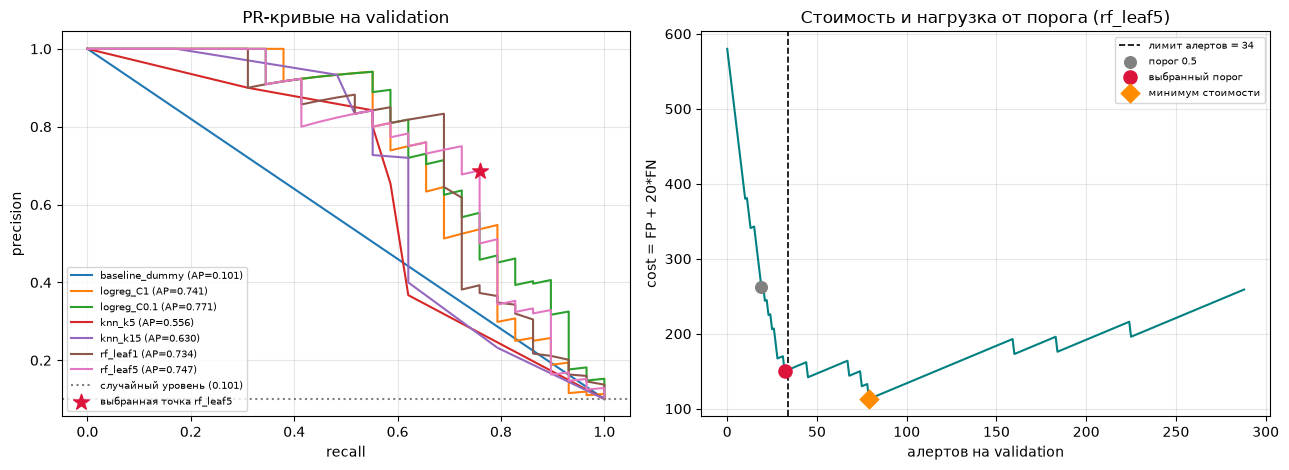

In [16]:
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name in CONFIGS:
    prec, rec, _ = precision_recall_curve(y_val, val_scores[name])
    axes[0].plot(rec, prec, linewidth=1.5, label=f'{name} (AP={VAL_METRICS.loc[name, "AP"]:.3f})')
axes[0].axhline(y_val.mean(), color='grey', linestyle=':', linewidth=1.5,
                label=f'случайный уровень ({y_val.mean():.3f})')
axes[0].scatter([ranked.iloc[0]['Recall']], [ranked.iloc[0]['Precision']], s=140, marker='*',
                color='crimson', zorder=5, label=f'выбранная точка {CHOSEN_CONFIG}')
axes[0].set_title('PR-кривые на validation')
axes[0].set_xlabel('recall')
axes[0].set_ylabel('precision')
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=7.5, loc='lower left')

axes[1].plot(tbl['Алертов'], tbl['cost'], color='teal', linewidth=1.5)
axes[1].axvline(ALLOWED_ALERTS, color='black', linestyle='--', linewidth=1.2,
                label=f'лимит алертов = {ALLOWED_ALERTS}')
axes[1].scatter([WORKING_POINTS.iloc[0]['Алертов']], [WORKING_POINTS.iloc[0]['cost = FP + 20*FN']],
                color='grey', s=70, zorder=5, label='порог 0.5')
axes[1].scatter([WORKING_POINTS.iloc[1]['Алертов']], [WORKING_POINTS.iloc[1]['cost = FP + 20*FN']],
                color='crimson', s=90, zorder=6, label='выбранный порог')
axes[1].scatter([min_cost_row['Алертов']], [min_cost_row['cost']], color='darkorange', s=90,
                marker='D', zorder=6, label='минимум стоимости')
axes[1].set_title(f'Стоимость и нагрузка от порога ({CHOSEN_CONFIG})')
axes[1].set_xlabel('алертов на validation')
axes[1].set_ylabel('cost = FP + 20*FN')
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=7.5)
plt.tight_layout()
plt.savefig(ARTIFACTS / 'validation_pr_and_cost.png', dpi=130)
plt.show()

**6.2. Вывод по порогу.** Правило «максимальный recall в пределах лимита» переводит выбранную модель из режима `predict()` (recall 0.552, 19 алертов, cost 263) в точку с recall 0.759 и cost 150: перехват растет на 20.7 п.п. при 32 алертах из 34 разрешенных (111 на 1000 событий). Минимум стоимости лежит дальше: порог 0.084 дает cost 113 при recall 0.897, но требует 79 алертов (27.4% событий), вдвое больше лимита. Ограничение емкости стоит 37 единиц стоимости (150 против 113, +33%) и 13.8 п.п. перехвата, зато нагрузка на аналитика падает в 2.5 раза. Оба варианта показаны в таблице: точка минимума стоимости недопустима по нагрузке, а `predict()` - по перехвату.

<div align="center">
<h1>7. Фиксация решения и однократная проверка на test</h1>
</div>

**7.1. Решение фиксируется до обращения к test.** Сохраняются обученный конвейер, порог, порядок признаков, правило score, справочники категорий, параметры разделения и метрики validation. После этого модель и порог не меняются, иначе оценка test перестает быть независимой. Файл `artifacts/detector.joblib` позволяет применить решение к новым событиям без повторного обучения.

In [17]:
import joblib

DECISION = {
    'positive_class': 1,
    'positive_class_meaning': 'is_suspicious = 1 (подозрительное событие по учебной разметке)',
    'score_rule': 'score = predict_proba(X)[:, 1]; alert = score >= threshold',
    'config': CHOSEN_CONFIG,
    'threshold': CHOSEN_THRESHOLD,
    'model': CHOSEN_PIPELINE,
    'features': FEATURES,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_features': CATEGORICAL_FEATURES,
    'allowed_categories': ALLOWED_CATEGORIES,
    'unknown_category': UNKNOWN_CATEGORY,
    'trained_on': {'rows': int(len(idx_train)), 'class1': int(y_train.sum())},
    'selected_on': {'part': 'validation', 'rows': int(len(idx_val)), 'class1': int(y_val.sum()),
                    'alert_limit_alerts': int(ALLOWED_ALERTS),
                    'alert_limit_share': ALERT_LIMIT_SHARE, 'fn_cost': FN_COST},
    'validation_metrics': {k: float(v) for k, v in ranked.iloc[0].drop(labels=['_порядок']).items()},
    'split': {'test_size': 0.2, 'random_state_valid': RS_VALID,
              'groups': GROUP_COLUMN, 'rows': {'train': int(len(idx_train)),
                                               'validation': int(len(idx_val)),
                                               'test': int(len(idx_test))}},
    'lab': 'ЛР № 2, вариант 2',
}
joblib.dump(DECISION, ARTIFACTS / 'detector.joblib')
print('Сохранено:', ARTIFACTS / 'detector.joblib',
      f'({(ARTIFACTS / "detector.joblib").stat().st_size / 1024:.0f} КБ)')

rule_table = pd.DataFrame([
    ['Объект анализа', 'одна попытка аутентификации (строка)'],
    ['Положительный класс', 'is_suspicious = 1'],
    ['Score', 'вероятность класса 1 моделью ' + CHOSEN_CONFIG],
    ['Правило алерта', f'score >= {CHOSEN_THRESHOLD:.6f}'],
    ['Лимит алертов', f'не более {1000 * ALERT_LIMIT_SHARE:.0f} на 1000 событий '
                      f'({ALLOWED_ALERTS} из {len(y_val)} на validation)'],
    ['Стоимость ошибок', f'cost = FP + {FN_COST} * FN'],
    ['Метрика выбора', 'recall в пределах лимита, затем precision, затем меньше алертов'],
    ['Обучено на', f'train: {len(idx_train)} строк, класс 1 = {int(y_train.sum())}'],
], columns=['Поле правила', 'Значение'])
display(rule_table)

Сохранено: artifacts\detector.joblib (1093 КБ)


,Поле правила,Значение
0,Объект анализа,одна попытка аутентификации (строка)
1,Положительный класс,is_suspicious = 1
2,Score,вероятность класса 1 моделью rf_leaf5
3,Правило алерта,score >= 0.185288
4,Лимит алертов,не более 120 на 1000 событий (34 из 288 на val...
5,Стоимость ошибок,cost = FP + 20 * FN
6,Метрика выбора,"recall в пределах лимита, затем precision, зат..."
7,Обучено на,"train: 862 строк, класс 1 = 79"


**7.2. Единственное обращение к test.** Внешний test (262 строки, те же события, что в ЛР № 1) оценивается один раз для зафиксированной пары «модель + порог». Никакие параметры после этого не подбираются.

In [18]:
# Единственная оценка зафиксированного решения на test
s_test = score_of(CHOSEN_PIPELINE, X_test)
pred_test = (s_test >= CHOSEN_THRESHOLD).astype(int)
tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()

TEST_METRICS = {
    'Конфигурация': CHOSEN_CONFIG,
    'threshold': round(CHOSEN_THRESHOLD, 4),
    'TP': int(tp_t), 'FP': int(fp_t), 'FN': int(fn_t), 'TN': int(tn_t),
    'Precision': precision_score(y_test, pred_test, zero_division=0),
    'Recall': recall_score(y_test, pred_test, zero_division=0),
    'F1': f1_score(y_test, pred_test, zero_division=0),
    'Accuracy': accuracy_score(y_test, pred_test),
    'AP': average_precision_score(y_test, s_test),
    'Алертов': int(tp_t + fp_t),
    'Алертов на 1000': 1000 * float(pred_test.mean()),
    'cost = FP + 20*FN': int(fp_t + FN_COST * fn_t),
}
print('Метрики на test (зафиксированное решение):')
display(pd.DataFrame([TEST_METRICS]).set_index('Конфигурация').round(3))

print(f'\nМатрица ошибок test (строки = истина, столбцы = прогноз):')
display(pd.DataFrame([[tn_t, fp_t], [fn_t, tp_t]], index=['истина 0', 'истина 1'],
                     columns=['прогноз 0', 'прогноз 1']))
print(f'Алертов: {TEST_METRICS["Алертов"]} из {len(y_test)} строк '
      f'({TEST_METRICS["Алертов на 1000"]:.0f} на 1000) при лимите {1000 * ALERT_LIMIT_SHARE:.0f} на 1000')
print('Доля класса 1 на test: {:.2%}'.format(y_test.mean()))

Метрики на test (зафиксированное решение):


,threshold,TP,FP,FN,TN,Precision,Recall,F1,Accuracy,AP,Алертов,Алертов на 1000,cost = FP + 20*FN
Конфигурация,,,,,,,,,,,,,
rf_leaf5,0.185,13,11,5,233,0.542,0.722,0.619,0.939,0.765,24,91.603,111



Матрица ошибок test (строки = истина, столбцы = прогноз):


,прогноз 0,прогноз 1
истина 0,233,11
истина 1,5,13


Алертов: 24 из 262 строк (92 на 1000) при лимите 120 на 1000
Доля класса 1 на test: 6.87%


**7.3. Сравнение validation и test.**

| Метрика | Validation (288 строк, класс 1 = 29) | Test (262 строки, класс 1 = 18) |
|---|---|---|
| AP (не зависит от порога) | 0.747 | 0.765 |
| Recall | 0.759 | 0.722 |
| Precision | 0.688 | 0.542 |
| F1 | 0.721 | 0.619 |
| Accuracy | 0.941 | 0.939 |
| Алертов на 1000 событий | 111 | 92 |
| cost = FP + 20*FN | 150 | 111 |

Recall на test практически такой же, как на validation: разница 3.7 п.п. меньше одного пропуска (один пропуск на test - это 5.6 п.п.), AP вырос с 0.747 до 0.765. Значит модель переносит закономерность на новые учетные записи, а не запоминает пользователей из train. Precision ниже (0.688 -> 0.542) в основном из-за меньшей доли класса 1 на test (6.87% против 10.07%): алертов на 1000 событий меньше (92 против 111), и доля настоящих срабатываний в очереди падает. Стоимость на test ниже (111 против 150), потому что событий и положительных объектов меньше.

Оценка test остается единственной: ни порог, ни модель, ни правило `unknown` по ее результатам не менялись.

<div align="center">
<h1>8. Разбор ошибок на test</h1>
</div>

**8.1. Ложные тревоги и пропуски.** Показываются до трех FP (высокий score у нормального события) и до трех FN (низкий score у подозрительного события) с ключом исходной строки, score, решением и признаками, по которым принимается решение.

In [19]:
res = df.iloc[idx_test].copy()
res['score'] = s_test
res['pred'] = pred_test
res['ошибка'] = np.select(
    [(res['pred'] == 1) & (res['is_suspicious'] == 0),
     (res['pred'] == 0) & (res['is_suspicious'] == 1)],
    ['FP', 'FN'], default='')

FP_ALL = res[res['ошибка'] == 'FP'].sort_values('score', ascending=False)
FN_ALL = res[res['ошибка'] == 'FN'].sort_values('score', ascending=False)
print('FP на test:', len(FP_ALL), '| FN на test:', len(FN_ALL))

show_cols = ['source_row_id', 'event_id', 'score', 'auth_method', 'failed_attempts_24h',
             'login_velocity_1h', 'distance_from_usual_km', 'new_country', 'vpn_used',
             'known_device', 'hour', 'is_weekend', 'account_age_days', 'department']
print('\nЛожные тревоги (FP), первые 3 из', len(FP_ALL), ':')
display(FP_ALL[show_cols].head(3).round(3))
print('Пропуски (FN), первые 3 из', len(FN_ALL), ':')
display(FN_ALL[show_cols].head(3).round(3))

print('\nСколько FP/FN дал бы собственный порог predict() (=0.5):')
pred_half = (s_test >= 0.5).astype(int)
print(' FP:', int(((pred_half == 1) & (y_test.values == 0)).sum()),
      '| FN:', int(((pred_half == 0) & (y_test.values == 1)).sum()),
      '| алертов:', int(pred_half.sum()))

FP на test: 11 | FN на test: 5

Ложные тревоги (FP), первые 3 из 11 :


,source_row_id,event_id,score,auth_method,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,new_country,vpn_used,known_device,hour,is_weekend,account_age_days,department
30,30,evt_001028,0.317,fido2,1.0,5,20000.0,0,0,1,11,1,2664.0,HR
498,502,evt_000230,0.314,password,4.0,8,66.5,0,0,1,16,1,2908.0,Finance
599,603,evt_retry_011,0.300,fido2,3.0,6,0.9,0,0,1,4,0,290.0,R&D


Пропуски (FN), первые 3 из 5 :


,source_row_id,event_id,score,auth_method,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,new_country,vpn_used,known_device,hour,is_weekend,account_age_days,department
1176,1190,evt_000923,0.157,password,1.0,4,43.4,0,0,0,14,0,338.0,SOC
416,420,evt_000809,0.149,push,1.0,4,14.2,0,0,0,11,0,799.0,R&D
187,188,evt_000528,0.144,push,0.0,1,48.2,0,0,0,3,0,3015.0,Operations



Сколько FP/FN дал бы собственный порог predict() (=0.5):
 FP: 0 | FN: 9 | алертов: 9


**8.2. Дополнительный разбор варианта 2: ошибки по `auth_method` и значения `failed_attempts_24h` у FN.** Разрез по способу аутентификации показывает, где выбранная рабочая точка перехватывает события, а где систематически пропускает. Значения `failed_attempts_24h` у FN проверяются, чтобы понять, есть ли у пропущенных событий общий признак серии неудачных попыток.

In [20]:
def auth_breakdown(frame):
    rows = []
    for method, g in frame.groupby('auth_method', dropna=False):
        tp = int(((g['pred'] == 1) & (g['is_suspicious'] == 1)).sum())
        fp = int(((g['pred'] == 1) & (g['is_suspicious'] == 0)).sum())
        fn = int(((g['pred'] == 0) & (g['is_suspicious'] == 1)).sum())
        rows.append({'auth_method': method, 'Событий': len(g),
                     'Класс 1': int(g['is_suspicious'].sum()),
                     'TP': tp, 'FP': fp, 'FN': fn,
                     'Recall': tp / (tp + fn) if (tp + fn) else np.nan,
                     'Precision': tp / (tp + fp) if (tp + fp) else np.nan})
    return pd.DataFrame(rows).set_index('auth_method')


TEST_BY_AUTH = auth_breakdown(res)
print('Ошибки по auth_method на test (выбранный порог):')
display(TEST_BY_AUTH.round(3))

val_frame = df.iloc[idx_val].copy()
val_frame['pred'] = (val_scores[CHOSEN_CONFIG] >= CHOSEN_THRESHOLD).astype(int)
VAL_BY_AUTH = auth_breakdown(val_frame)
print('Тот же разрез на validation (для сравнения устойчивости):')
display(VAL_BY_AUTH.round(3))

print('\nfailed_attempts_24h у ложных пропусков (test):',
      FN_ALL['failed_attempts_24h'].value_counts(dropna=False).to_dict())
print('failed_attempts_24h у перехваченных событий (test):',
      res[(res['pred'] == 1) & (res['is_suspicious'] == 1)]['failed_attempts_24h']
      .value_counts(dropna=False).to_dict())
print('failed_attempts_24h у ложных пропусков (validation):',
      val_frame[(val_frame['pred'] == 0) & (val_frame['is_suspicious'] == 1)]
      ['failed_attempts_24h'].value_counts(dropna=False).to_dict())

Ошибки по auth_method на test (выбранный порог):


,Событий,Класс 1,TP,FP,FN,Recall,Precision
auth_method,,,,,,,
fido2,66,5,5,6,0,1.000,0.455
otp,37,4,3,1,1,0.750,0.750
password,66,3,1,3,2,0.333,0.250
push,93,6,4,1,2,0.667,0.800


Тот же разрез на validation (для сравнения устойчивости):


,Событий,Класс 1,TP,FP,FN,Recall,Precision
auth_method,,,,,,,
fido2,8,0,0,0,0,NaN,NaN
otp,64,6,3,2,3,0.500,0.600
password,165,19,15,3,4,0.789,0.833
push,51,4,4,5,0,1.000,0.444



failed_attempts_24h у ложных пропусков (test): {1.0: 4, 0.0: 1}
failed_attempts_24h у перехваченных событий (test): {2.0: 5, 1.0: 3, 3.0: 2, 0.0: 2, 5.0: 1}
failed_attempts_24h у ложных пропусков (validation): {1.0: 4, 0.0: 1, nan: 1, 2.0: 1}


**8.3. Что показывают ошибки.**

*Ложные тревоги (11 из 24 алертов).* Нормальные события с одним экстремальным признаком: поездка на 20000 км (`source_row_id = 30`), 4 неудачные попытки при `login_velocity_1h = 8` (строка 502), повторная попытка `evt_retry_011` при `known_device = 1`. Для леса такой экстремум - сильный раскол, и score превышает порог 0.184 даже без подозрительного контекста. У 6 из 11 FP способ входа `fido2` - самый редкий в наборе.

*Ложные пропуски (5 из 18).* «Тихие» подозрительные события: у 4 из 5 `failed_attempts_24h = 1` (у перехваченных чаще 2-5), `known_device = 0`, `new_country = 0`, `vpn_used = 0`, расстояние 14-48 км. Ни один простой признак не выделяет их на фоне нормы, поэтому score не выше 0.157 не дотягивает до порога 0.184. Ловить такие события можно только производными признаками (серии событий по `user_id`, время между попытками), которых в наборе нет.

*Разрез по `auth_method`.* `fido2` - перехвачено 5 из 5, но 6 ложных тревог (precision 0.455); `push` - 4 из 6 при одной ложной тревоге (precision 0.800); `password` - 1 из 3 (recall 0.333); `otp` - 3 из 4. На validation по `password` картина обратная (recall 0.789 при precision 0.833), поэтому разрез описательный: в test всего 3 подозрительных события с `password`, и один промах сразу дает recall 0.333.

*Дополнительный разбор варианта 2.* `failed_attempts_24h` разделяет перехваченные и пропущенные события: у TP значения 2-5 встречаются часто, у FN - только 0 и 1 (4 случая из 5). Признак серии неудачных попыток работает, но события без серии остаются за порогом. Чтобы их не пропускать, нужно снижать порог (нарушая лимит) или добавлять признаки истории пользователя, а не менять модель.

In [21]:
# Сохранение сводных таблиц для отчета
VAL_METRICS.round(4).to_csv(ARTIFACTS / 'validation_model_metrics.csv')
BEST_VALID.round(4).to_csv(ARTIFACTS / 'validation_threshold_points.csv')
WORKING_POINTS.round(4).to_csv(ARTIFACTS / 'validation_working_points.csv')
TEST_BY_AUTH.round(4).to_csv(ARTIFACTS / 'test_by_auth_method.csv')
pd.DataFrame([TEST_METRICS]).set_index('Конфигурация').round(4).to_csv(ARTIFACTS / 'test_metrics.csv')
AUDIT.to_csv(ARTIFACTS / 'cleaning_audit.csv', index=False)
CAT_AUDIT.to_csv(ARTIFACTS / 'categorical_audit.csv')
print('Сохранены таблицы:', sorted(p.name for p in ARTIFACTS.iterdir()))

Сохранены таблицы: ['categorical_audit.csv', 'cleaning_audit.csv', 'detector.joblib', 'split_ids.csv', 'test_by_auth_method.csv', 'test_metrics.csv', 'validation_model_metrics.csv', 'validation_pr_and_cost.png', 'validation_threshold_points.csv', 'validation_working_points.csv']


<div align="center">
<h1>9. Вывод</h1>
</div>

1. Протокол ЛР № 1 воспроизведен полностью: внешний test состоит из тех же 262 строк и 24 групп `user_id`, что в отчете ЛР № 1, разделение осталось групповым по `user_id`, пересечений групп между train (862 строки, 72 группы), validation (288 строк, 24 группы) и test (262 строки, 24 группы) нет.
2. Очистка перенесена из ЛР № 1: 18 непустых категориальных значений вне справочника заменены на `unknown`, 4 невалидные непустые метки времени переведены в `NaT`, 18 полных дубликатов удалены; осталось 1412 строк и 126 событий класса 1 (8.92%).
3. На validation при собственном пороге `predict()` все модели близки (recall 0.552-0.586), поэтому сравнивались они по AP: лучшие `logreg_C0.1` (0.771) и `rf_leaf5` (0.747), KNN отстает (0.630 и 0.556) из-за разреженного one-hot пространства.
4. Baseline `DummyClassifier` дает AP 0.101 и accuracy 0.899 при нулевом recall, поэтому accuracy в этой задаче ничего не показывает, а нижняя граница по AP равна доле класса 1.
5. Зафиксировано решение `rf_leaf5` с порогом 0.185288: на validation TP 22, FP 10, FN 7, recall 0.759, precision 0.688, 32 алерта из 34 разрешенных и cost 150.
6. Основной прирост дал именно подбор порога по validation: по сравнению с `predict()` (recall 0.552, cost 263) перехват вырос на 20.7 п.п. и остался в пределах лимита 12% алертов.
7. Минимум стоимости (порог 0.084, recall 0.897, cost 113) требовал 79 алертов, вдвое больше лимита, поэтому выбранная точка дороже минимума на 37 единиц (+33%) и теряет 13.8 п.п. перехвата - это и есть цена ограниченной емкости проверки.
8. На test зафиксированное решение дало TP 13, FP 11, FN 5, recall 0.722, precision 0.542, F1 0.619, AP 0.765, 24 алерта (92 на 1000 событий) и cost 111: recall сохранился на уровне validation, precision ниже из-за меньшей доли класса 1 (6.87% против 10.07%).
9. Ошибки не случайны: ложные тревоги - нормальные события с одним экстремальным признаком (расстояние 20000 км, `login_velocity_1h = 8`), а пропуски - «тихие» подозрительные события с `failed_attempts_24h = 1` и обычными значениями остальных признаков.
10. Ограничение по данным: набор синтетический и размечен учебно, положительных событий мало (29 на validation, 18 на test), поэтому один пропуск меняет recall на 3.4 и 5.6 п.п., а различия метрик между частями статистически не значимы.
11. Ограничение по разделению: validation получена одной выборкой по 24 группам `user_id` и проверяет только сценарий новых учетных записей, а не новые источники входа или будущие события, поэтому порог и сравнение моделей чувствительны к составу групп.
12. Ограничение по переносу: порог и лимит 12% привязаны к этой validation и к доле класса 1 в ней, а score леса - доля голосов деревьев, а не калиброванная вероятность; в рабочем потоке порог нужно пересчитывать на свежих данных, поэтому классификатор пригоден для маршрутизации ручной проверки, но не для автоматической блокировки.

<div align="center">
<h1>Версии библиотек и артефакты</h1>
</div>

Раздел закрывает требования к воспроизводимости: версии основных библиотек и перечень сохраненных артефактов.

In [22]:
import sklearn as _sk
requirements = pd.DataFrame({
    'Пакет': ['python', 'pandas', 'numpy', 'scikit-learn', 'matplotlib', 'joblib'],
    'Версия': [sys.version.split()[0], pd.__version__, np.__version__,
               _sk.__version__, matplotlib.__version__, joblib.__version__],
})
display(requirements)
print('Артефакты работы:')
for path in sorted(ARTIFACTS.iterdir()):
    print(f'  {path.name:38s} {path.stat().st_size / 1024:8.1f} КБ')
print('\nГотово: модель, порог и таблицы сохранены в', ARTIFACTS.resolve())

,Пакет,Версия
0,python,3.12.10
1,pandas,3.1.1
2,numpy,2.5.4
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,joblib,1.6.0


Артефакты работы:
  categorical_audit.csv                       0.3 КБ
  cleaning_audit.csv                          1.0 КБ
  detector.joblib                          1093.1 КБ
  split_ids.csv                              42.9 КБ
  test_by_auth_method.csv                     0.2 КБ
  test_metrics.csv                            0.2 КБ
  validation_model_metrics.csv                1.0 КБ
  validation_pr_and_cost.png                135.7 КБ
  validation_threshold_points.csv             0.6 КБ
  validation_working_points.csv               0.5 КБ

Готово: модель, порог и таблицы сохранены в C:\Users\jrzen\OneDrive\Документы\GitHub\medved02\artifacts
